# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
# !pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

# %pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph


In [2]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


GPU available: False
scanpy 1.11.5 | squidpy 1.8.2


/var/folders/6w/v5jxyfdn3ls0th9p12pz41v80000gn/T/ipykernel_9176/1236436484.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


In [3]:
import scanpy as sc
import squidpy as sq
import cellxgene_census
import scvi
import harmonypy

print("Mac environment is ready!")

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Mac environment is ready!


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [4]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'ovarian cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 57,783


/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



18,000 cells from 9 donors
cell_type_broad
T                   8445
Fibroblast          4025
Other               2544
Epithelial/Tumor    1620
B                    840
Endothelial          526
Name: count, dtype: int64


/var/folders/6w/v5jxyfdn3ls0th9p12pz41v80000gn/T/ipykernel_9176/1836815281.py:28: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


In [5]:

print("Cells before QC:", adata.n_obs)
print("Genes before QC:", adata.n_vars)
print("Donors before QC:", adata.obs["donor_id"].nunique())


Cells before QC: 18000
Genes before QC: 61497
Donors before QC: 9


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [6]:

print("Available metadata columns:")
print(adata.obs.columns.tolist())

if "disease" in adata.obs.columns:
    print("\nDisease:")
    print(adata.obs["disease"].value_counts())
else:
    print("\nDisease column is not available.")


Available metadata columns:
['donor_id', 'assay', 'cell_type', 'disease', 'sex', 'cell_type_broad']

Disease:
disease
ovarian cancer                                                          18000
Alzheimer disease                                                           0
macular degeneration                                                        0
leukoencephalopathy, diffuse hereditary, with spheroids 1                   0
listeriosis                                                                 0
                                                                        ...  
dementia || Alzheimer disease || frontotemporal dementia                    0
dementia || Alzheimer disease || normal pressure hydrocephalus              0
dementia || Alzheimer disease || schizophrenia                              0
dementia || Alzheimer disease || schizophrenia || Lewy body dementia        0
vascular dementia || progressive supranuclear palsy                         0
Name: count, Length: 259

In [7]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat", batch_key="donor_id")
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 17947


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [8]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca", transformer="sklearn")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

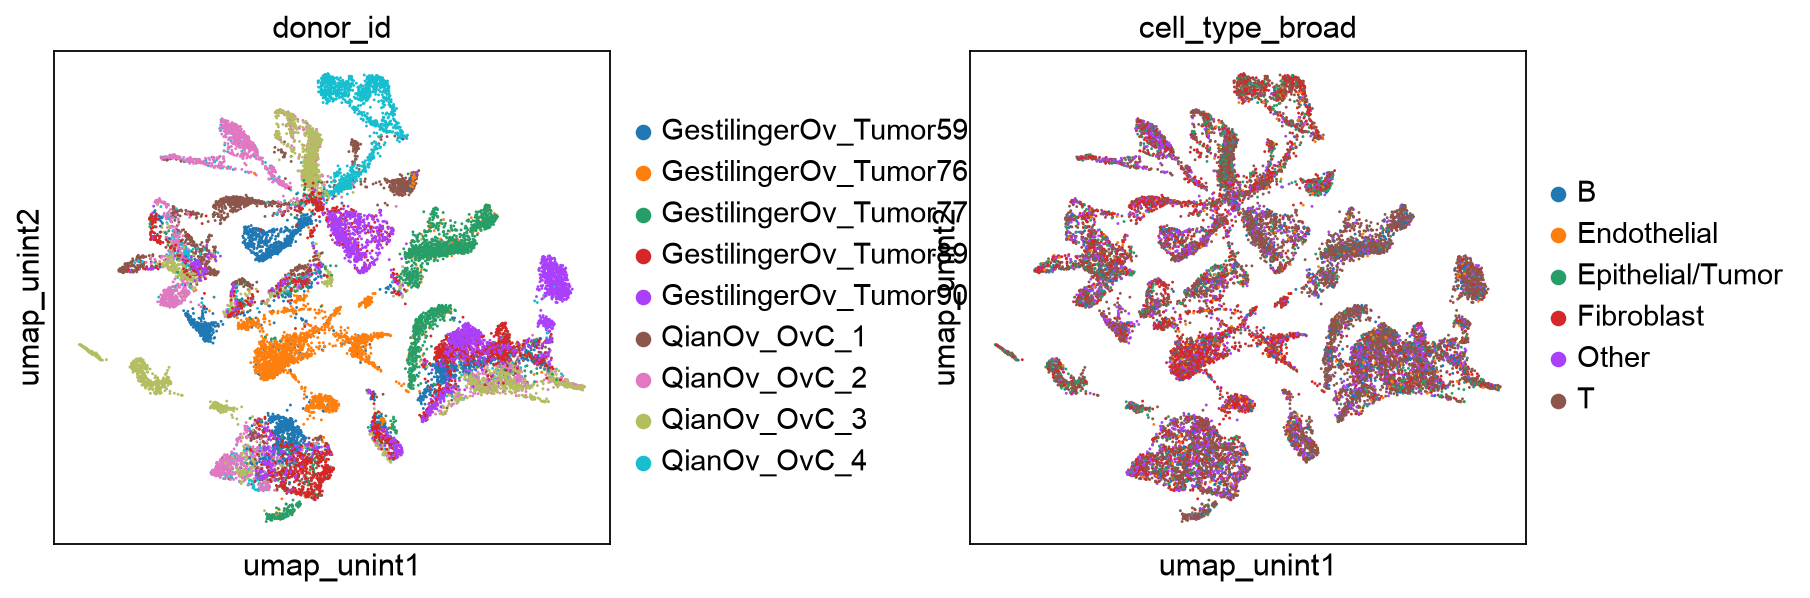

In [9]:
# TODO: plot the unintegrated UMAP colored by donor and by cell type.
# hint: sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5)
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5)


**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

*Your answer here.* The unintegrated UMAP shows partial clustering by donor, suggesting possible batch effects. Different cell types overlap across several regions, indicating that both donor variation and biological differences may influence the clustering.

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [10]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=60, accelerator="mps", devices=1)
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI", transformer="sklearn")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/en

Training:   0%|          | 0/60 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.


scVI done


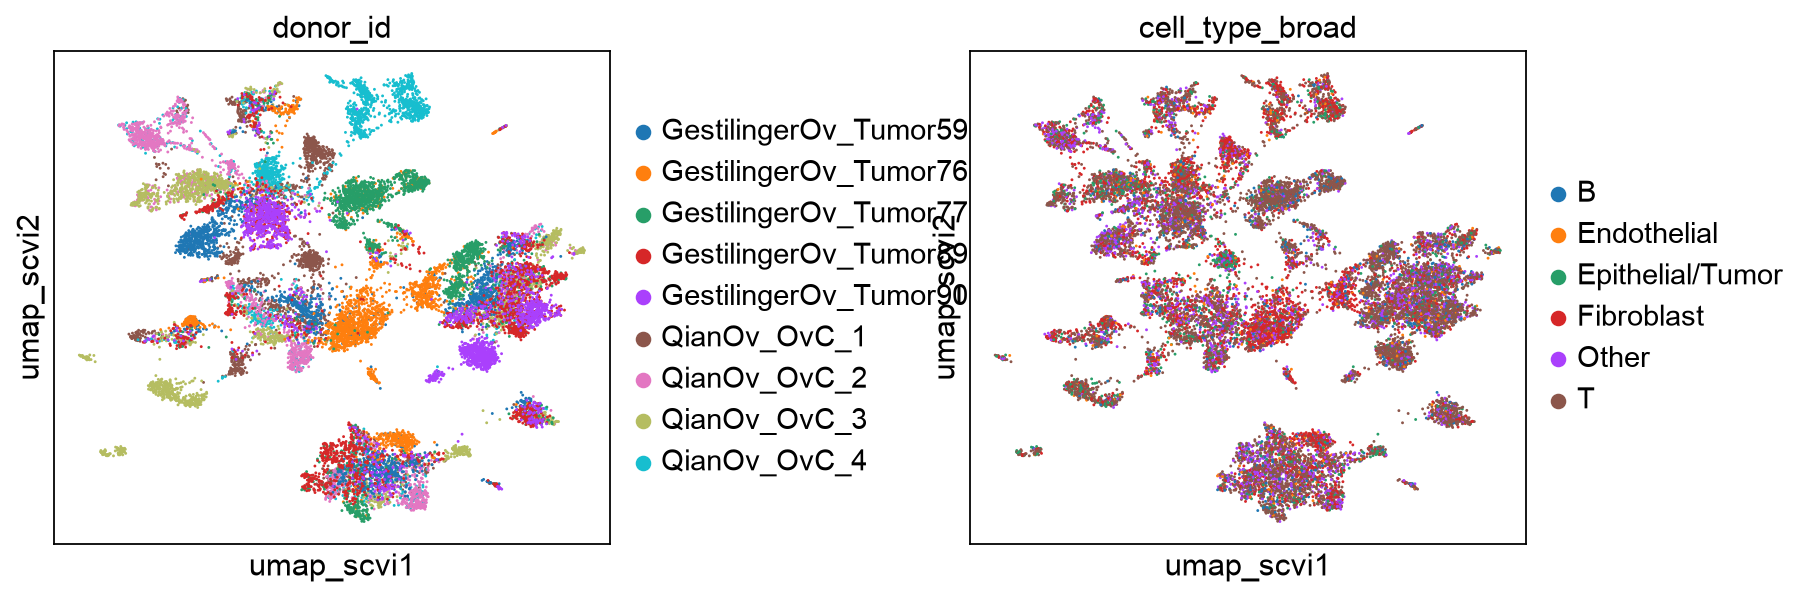

In [11]:
# TODO: plot the scVI UMAP colored by donor and by cell type. Did the donors mix?
# hint: sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5)
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5)


## 1.5 · Harmony, a fair baseline  *(provided)*

In [12]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-24 11:23:13,610 - harmonypy - INFO - Running Harmony
2026-11-24 11:23:13,610 - harmonypy - INFO -   Parameters:
2026-11-24 11:23:13,610 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-24 11:23:13,610 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-24 11:23:13,611 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-24 11:23:13,611 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-24 11:23:13,611 - harmonypy - INFO -     nclust: 100
2026-11-24 11:23:13,612 - harmonypy - INFO -     block_size: 0.05
2026-11-24 11:23:13,612 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-24 11:23:13,613 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-11-24 11:23:13,613 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-24 11:23:13,613 - harmonypy - INFO -     verbose: True
2026-11-24 11:23:13,614 - harmonypy - INFO -     random_state: 0
2026-11-24 11:23:13,614 - harmonypy - INFO -   Data: 50 PCs × 17947 cells
2026-11-24 11:23:13,614 - har

Harmony done


## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

In [13]:
from sklearn.metrics import silhouette_score
# TODO: for each embedding, score batch mixing (by donor_id, lower is better)
#       and biology preservation (by cell_type_broad, higher is better).
# hint:
# idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
# reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
# for name, key in reps.items():
#     emb = adata.obsm[key][idx]
#     batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
#     bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
#     print(name, round(batch,3), round(bio,3))
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    print(name, round(batch,3), round(bio,3))

No integration 0.014 -0.028
Harmony -0.059 -0.03
scVI -0.002 -0.018


**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

*Your answer here.* I would choose scVI because it has a batch score closer to zero (-0.002) and a slightly higher cell-type score (-0.018) than Harmony. However, the differences are small, so scVI does not clearly outperform Harmony.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

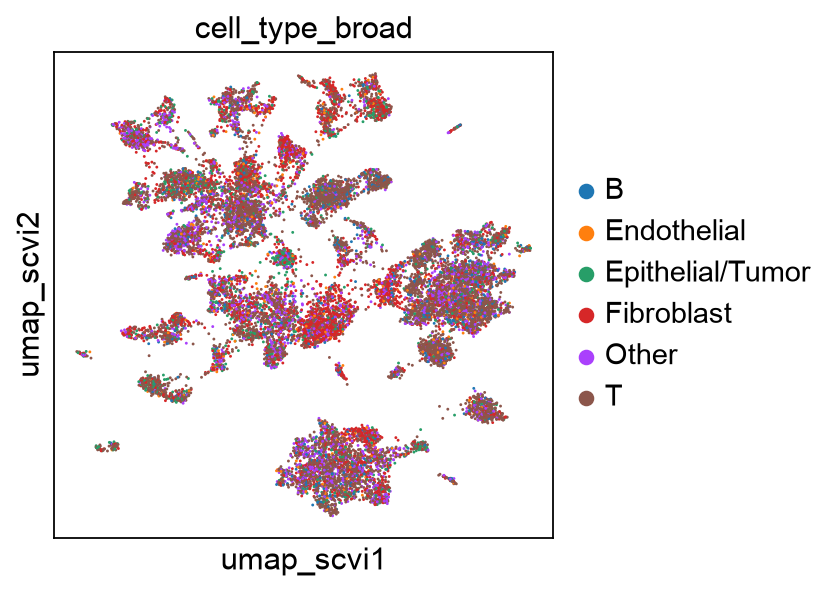

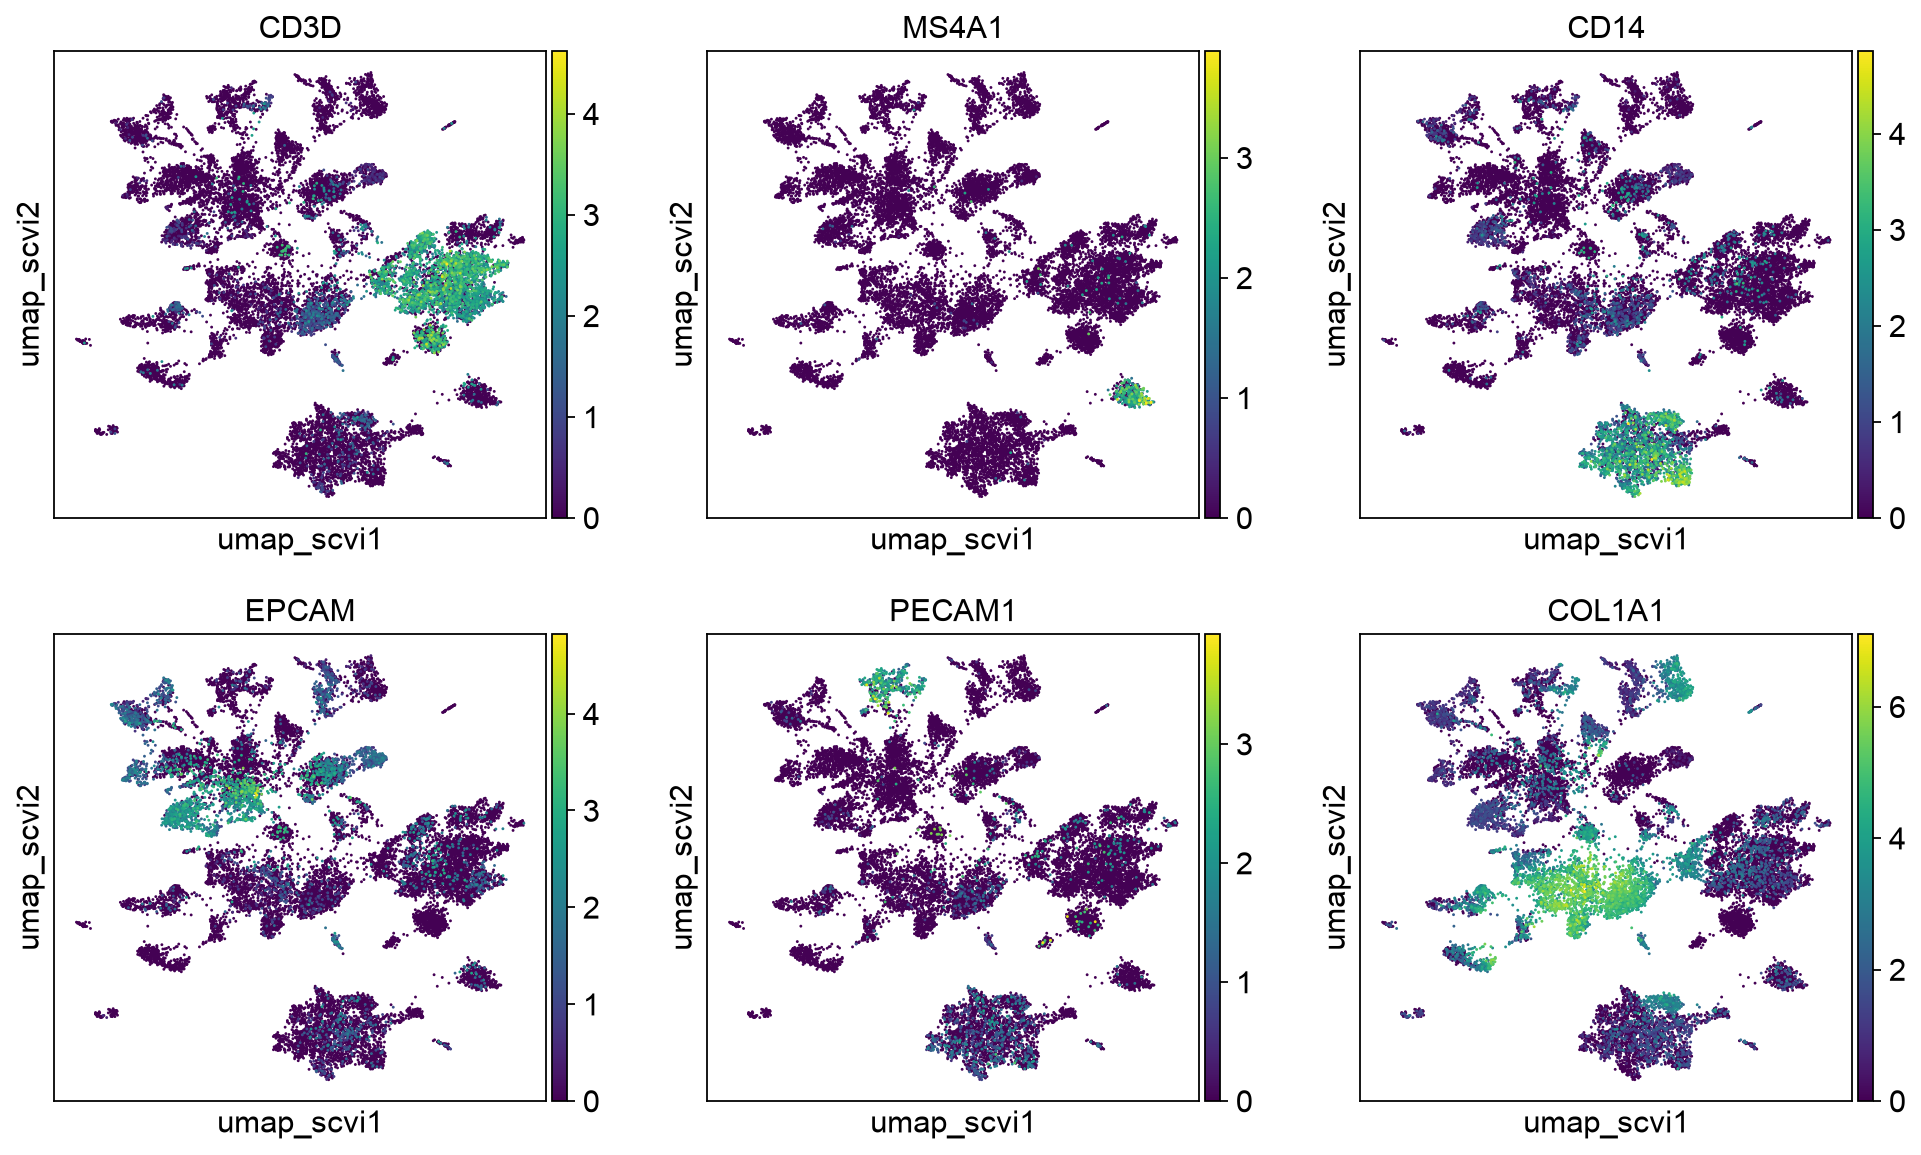

In [14]:
# TODO: plot the scVI UMAP colored by cell_type_broad, and by canonical markers.
# hint:
# sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad")
# markers = [g for g in ["CD3D","MS4A1","CD14","EPCAM","PECAM1","COL1A1"] if g in adata.raw.var_names]
# sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad")
markers = [g for g in ["CD3D","MS4A1","CD14","EPCAM","PECAM1","COL1A1"] if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

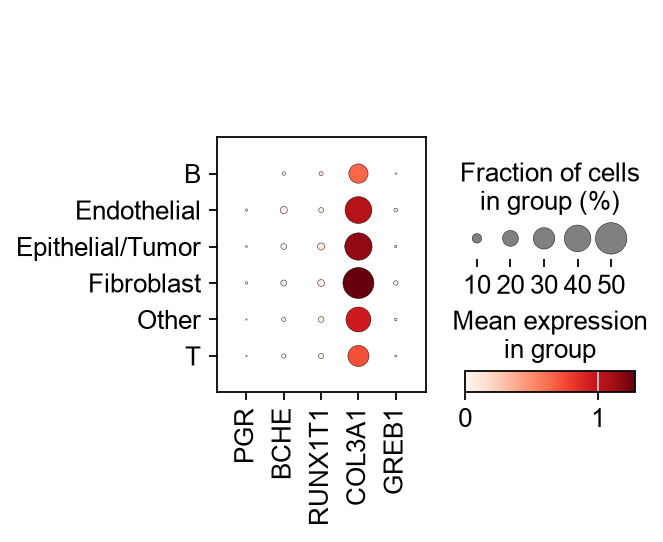

In [15]:
candidate_genes = ["PGR", "BCHE", "RUNX1T1", "COL3A1", "GREB1"]

available_genes = [
    gene for gene in candidate_genes
    if gene in adata.raw.var_names
]

sc.pl.dotplot(
    adata,
    var_names=available_genes,
    groupby="cell_type_broad",
    use_raw=True
)

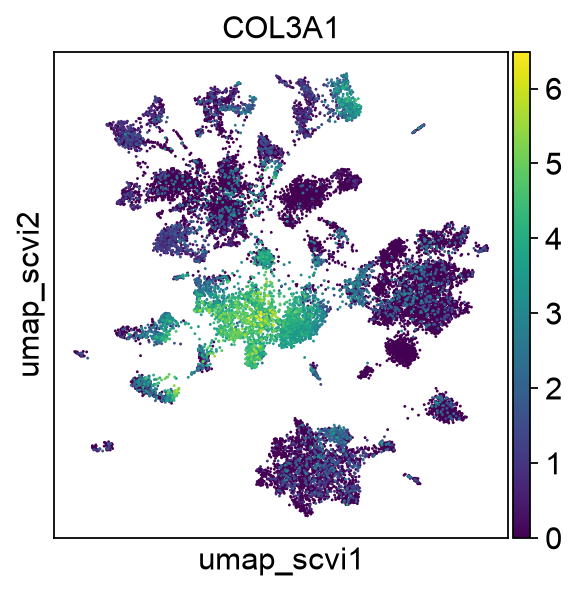

In [16]:
TARGET = "COL3A1"   # TODO: choose your target: ERBB2, ESR1, EPCAM, MKI67, PTPRC, CD68, CD3D, or your Part I gene
# TODO: plot TARGET on the scVI UMAP.
# hint: sc.pl.embedding(adata, basis="umap_scvi", color=TARGET, use_raw=True)
sc.pl.embedding(adata, basis="umap_scvi", color=TARGET, use_raw=True)


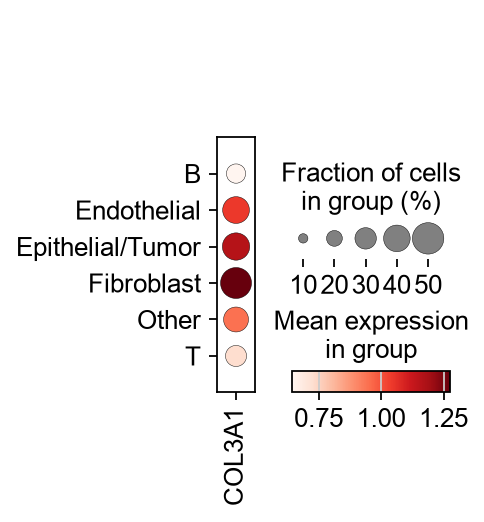

In [17]:
sc.pl.dotplot(
    adata,
    var_names=["COL3A1"],
    groupby="cell_type_broad",
    use_raw=True
)

**TODO (interpretation):** Which cell type(s) express your target? 

*Your answer here.* COL3A1 shows the highest expression in fibroblasts, followed by epithelial/tumor and endothelial cells. The UMAP also shows concentrated expression in specific cell clusters.

---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [18]:
import scanpy as sc

spatial = sc.read_visium(
    path="data",
    count_file="Visium_FFPE_Human_Ovarian_Cancer_filtered_feature_bc_matrix.h5",
    load_images=True
)

spatial.var_names_make_unique()

print(spatial)
print("Spots x Genes:", spatial.shape)
print("Spatial coordinates:", spatial.obsm["spatial"].shape)
print("Spatial metadata:", list(spatial.uns["spatial"].keys()))


/var/folders/6w/v5jxyfdn3ls0th9p12pz41v80000gn/T/ipykernel_9176/4253557587.py:3: FutureWarning: Use `squidpy.read.visium` instead.
  spatial = sc.read_visium(
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 3455 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
Spots x Genes: (3455, 17943)
Spatial coordinates: (3455, 2)
Spatial metadata: ['Visium_FFPE_Human_Ovarian_Cancer']


## 2.2 · Pipeline and clustering  *(provided)*

In [19]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/var/folders/6w/v5jxyfdn3ls0th9p12pz41v80000gn/T/ipykernel_9176/4117200164.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 7


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

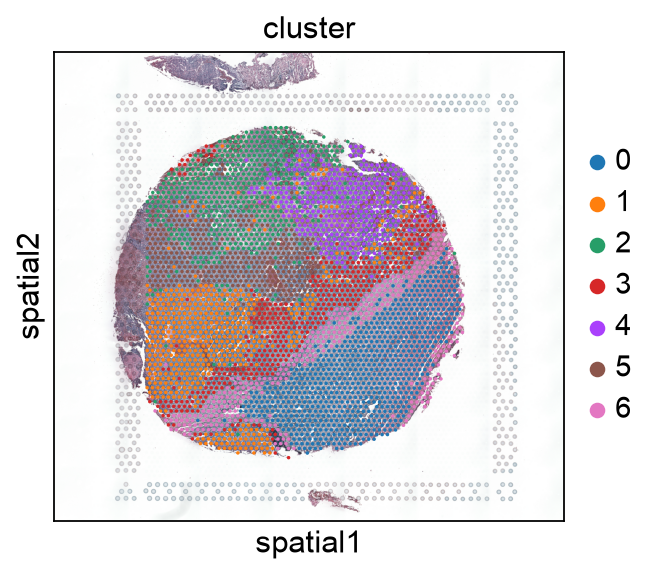

In [20]:
# TODO: plot the clusters on the tissue image.
# hint: sq.pl.spatial_scatter(spatial, color="cluster")
sq.pl.spatial_scatter(spatial, color="cluster")

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

*Your answer here.* The seven spatial clusters show distinct regional patterns within the ovarian cancer tissue. These regions may reflect tumor, stromal, or immune areas, but additional marker analysis is needed to confirm their identities.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [21]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/6w/v5jxyfdn3ls0th9p12pz41v80000gn/T/ipykernel_9176/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


               I
C7      0.933815
DCN     0.912999
ACTA2   0.903745
MGP     0.902931
MYLK    0.892221
IGFBP5  0.886841
ACTG2   0.884689
AEBP1   0.881424


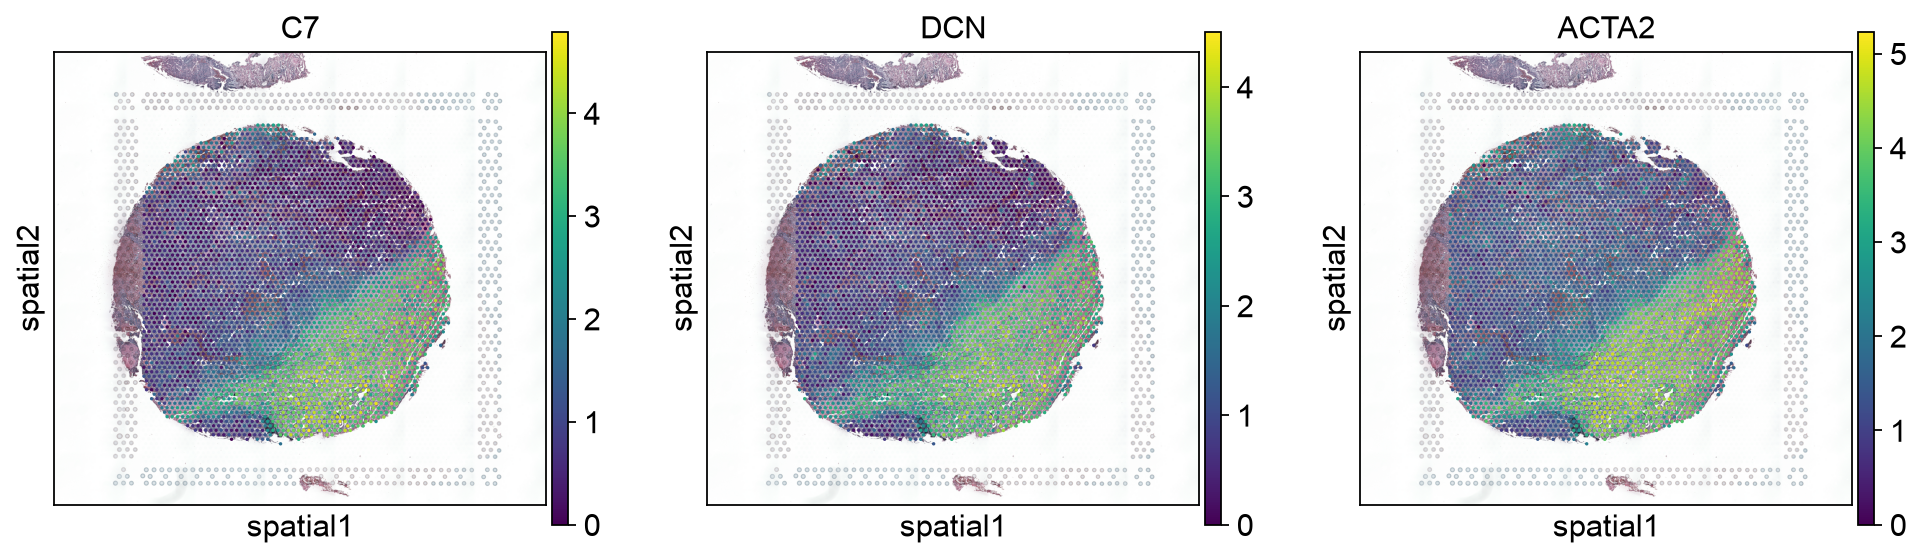

In [22]:
# TODO: compute Moran's I, print the top spatially variable genes, and plot 2-3 on the tissue.
# hint:
# sq.gr.spatial_autocorr(spatial, mode="moran")
# top = spatial.uns["moranI"].head(8); print(top[["I"]])
# sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist())
sq.gr.spatial_autocorr(spatial, mode="moran")
top = spatial.uns["moranI"].head(8); print(top[["I"]])
sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist())


## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

  0%|          | 0/1000 [00:00<?, ?/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


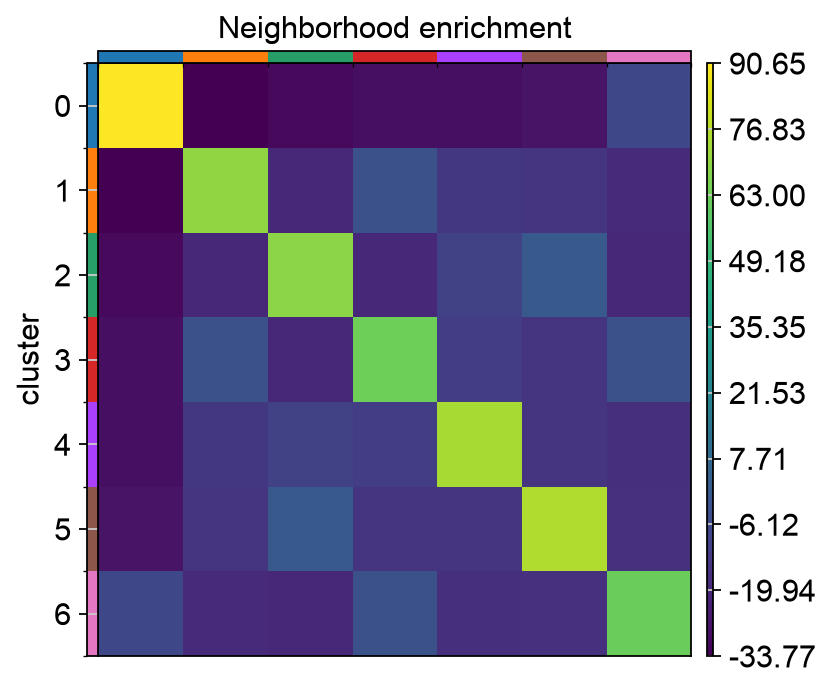

In [23]:
# TODO: run and plot neighborhood enrichment across the clusters.
# hint:
# sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
# sq.pl.nhood_enrichment(spatial, cluster_key="cluster")
sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster")

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

*Your answer here.* The heatmap shows strong within-cluster neighborhood enrichment, while most between-cluster interactions are weak or depleted. A tumor–immune boundary cannot be confirmed without additional cell-type markers.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

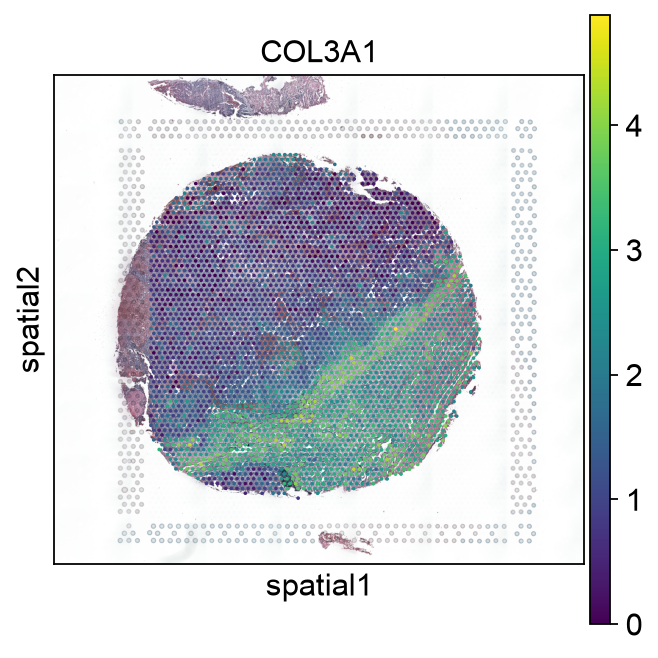

In [24]:
# TODO: plot TARGET on the tissue (if it is present in this section).
# hint:
# if TARGET in spatial.raw.var_names:
#     sq.pl.spatial_scatter(spatial, color=TARGET)
# else:
#     print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")
if TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(spatial, color=TARGET)
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")



**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

*Your answer here.* COL3A1 shows higher expression in the lower and right regions of the ovarian cancer tissue, with lower expression in the upper regions. However, the plot alone cannot confirm whether these areas represent the tumor core, invasive margin, or immune niches.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.